# 01 — Data Audit: UCI Default of Credit Card Clients

**Purpose.** Inspect the original dataset before any modelling: schema, target definition, data-quality issues, and the reproducible data split.

**Source.** UCI Machine Learning Repository, dataset 350 (Yeh, 2016 donation; DOI 10.24432/C55S3H; licence CC BY 4.0).
The raw file in `data/raw/` is read-only; this notebook does not modify it.

All logic lives in `src/credit_risk/` and is covered by tests. The notebook only calls it and displays the results.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd

from credit_risk.config import load_config, resolve_path
from credit_risk.data import (BILL_AMOUNTS, PAY_AMOUNTS, PAY_STATUS, TARGET, DataSplits,
                              file_sha256, load_raw, standardize_columns)
from credit_risk.validation import data_quality_report, validate_raw_schema

cfg = load_config("data")
RAW_PATH = resolve_path(cfg["dataset"]["raw_path"])
FIG_DIR = resolve_path("reports/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#1f1f1f", "#6b6b6b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e6", "axes.edgecolor": MUTED, "axes.labelcolor": INK,
                     "figure.dpi": 110, "axes.axisbelow": True})
pd.set_option("display.width", 140)

## 1. Raw file and schema
The Excel file has two header rows: generic names (`X1 … X23`, `Y`) and descriptive names. We use the descriptive row.

In [2]:
print("SHA-256:", file_sha256(RAW_PATH))
raw = load_raw(RAW_PATH, expected_sha256=cfg["dataset"]["expected_sha256"])
validate_raw_schema(raw, expected_rows=cfg["dataset"]["expected_rows"])
print("Schema validation passed:", raw.shape)
raw.head()

SHA-256: 30c6be3abd8dcfd3e6096c828bad8c2f011238620f5369220bd60cfc82700933


Schema validation passed: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:
df = standardize_columns(raw)
df.dtypes.value_counts()

int64    25
Name: count, dtype: int64

**Renaming.** `PAY_0` → `PAY_1` (so index 1 is September 2005 in all three monthly blocks), and `default payment next month` → `default_next_month`.

**Target.** `default_next_month = 1` means the client defaulted on the payment due in the month after the observation window (October 2005). The UCI page doesn't define "default" any more precisely than that, which is a limitation of the dataset.

In [4]:
rate = df[TARGET].mean()
print(f"Observations: {len(df):,}   Defaults: {df[TARGET].sum():,}   Default rate: {rate:.2%}")

Observations: 30,000   Defaults: 6,636   Default rate: 22.12%


## 2. Data-quality report

In [5]:
report = data_quality_report(df)
print(json.dumps({k: report[k] for k in ["missing_values_total", "id_unique",
      "rows_with_undocumented_demographic_code", "inactive_accounts_all_zero_bills_and_payments",
      "duplicate_feature_rows_excluding_id", "duplicate_feature_groups_with_conflicting_target",
      "bill_exceeds_limit_rows"]}, indent=2))

{
  "missing_values_total": 0,
  "id_unique": true,
  "rows_with_undocumented_demographic_code": 399,
  "inactive_accounts_all_zero_bills_and_payments": 795,
  "duplicate_feature_rows_excluding_id": 56,
  "duplicate_feature_groups_with_conflicting_target": 21,
  "bill_exceeds_limit_rows": 3931
}


In [6]:
pd.DataFrame(report["undocumented_codes"]).fillna(0).astype(int).T.rename_axis("column")

,0,5,6,-2
column,,,,
SEX,0,0,0,0
EDUCATION,14,280,51,0
MARRIAGE,54,0,0,0
PAY_1,14737,0,0,2759
PAY_2,15730,0,0,3782
PAY_3,15764,0,0,4085
PAY_4,16455,0,0,4348
PAY_5,16947,0,0,4546
PAY_6,16286,0,0,4895


In [7]:
pd.DataFrame({"negative_bill_rows": report["negative_bill_amounts"]}).T

,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6
negative_bill_rows,590,669,655,675,655,688


**Findings**

| Issue | Observation | Treatment (decided in Phase 2, applied inside the pipeline) |
|---|---|---|
| `EDUCATION` codes 0, 5, 6 | 345 rows; not in the UCI description (1–4 only) | Candidate: merge into 4 = "others"; compare with keeping them separate |
| `MARRIAGE` code 0 | 54 rows; not documented (1–3) | Candidate: merge into 3 = "others" |
| `PAY_*` codes −2 and 0 | most rows; UCI documents only −1 and 1–9 | Treat `PAY_*` as **ordinal**, and add a "no delay" indicator (≤ 0). Usually read as −2 = no consumption, 0 = revolving credit, but that reading is not in the official documentation |
| Negative `BILL_AMT` | ~2% of rows per month | Plausible credit balances (overpayment); keep |
| Inactive accounts | 795 rows with zero bills and payments for all 6 months | Keep; candidate indicator feature |
| Bill above limit | 3,931 rows where some month's bill exceeds `LIMIT_BAL` | Plausible (interest, fees, over-limit); utilisation features will be capped only if justified |
| Duplicate feature vectors | 56 rows duplicate another row's features (excluding ID); 21 duplicate groups have conflicting targets | Different customers with identical records (often inactive). Keep; minor leakage risk across splits, documented |
| Missing values | none | Imputers still included in pipelines to handle Explorer inputs safely |

## 3. Target and key relationships (observed rates, not model predictions)

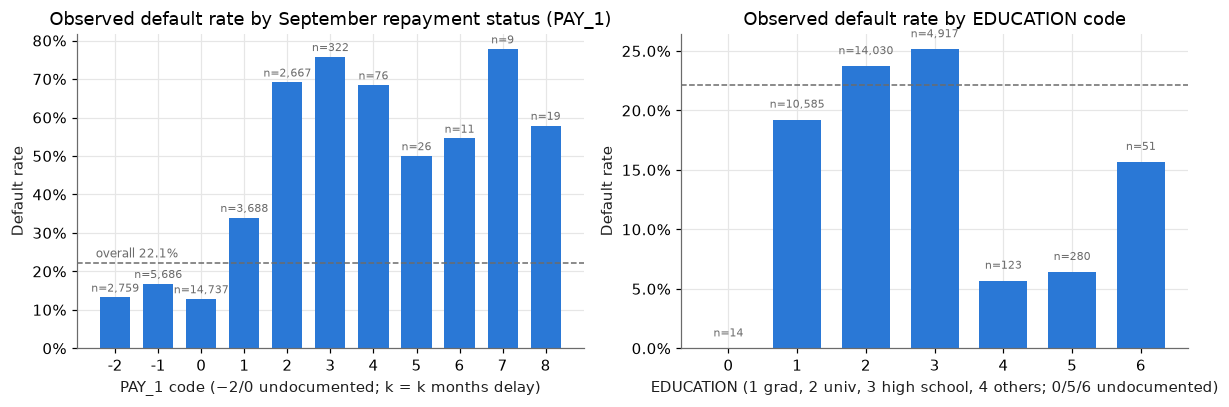

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
status = df.groupby("PAY_1")[TARGET].agg(["mean", "size"])
axes[0].bar(status.index.astype(str), status["mean"], color=BLUE, width=0.7)
axes[0].axhline(rate, color=MUTED, ls="--", lw=1); axes[0].text(-0.45, rate+0.015, f"overall {rate:.1%}", color=MUTED, ha="left", fontsize=8)
axes[0].set(title="Observed default rate by September repayment status (PAY_1)", xlabel="PAY_1 code (−2/0 undocumented; k = k months delay)", ylabel="Default rate")
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
for x, (m, n) in enumerate(status.itertuples(index=False)):
    axes[0].text(x, m + 0.015, f"n={n:,}", ha="center", fontsize=7, color=MUTED)
edu = df.groupby("EDUCATION")[TARGET].agg(["mean", "size"])
axes[1].bar(edu.index.astype(str), edu["mean"], color=BLUE, width=0.7)
axes[1].axhline(rate, color=MUTED, ls="--", lw=1)
axes[1].set(title="Observed default rate by EDUCATION code", xlabel="EDUCATION (1 grad, 2 univ, 3 high school, 4 others; 0/5/6 undocumented)", ylabel="Default rate")
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
for x, (m, n) in enumerate(edu.itertuples(index=False)):
    axes[1].text(x, m + 0.01, f"n={n:,}", ha="center", fontsize=7, color=MUTED)
fig.tight_layout(); fig.savefig(FIG_DIR / "01_default_rate_by_pay1_education.png", bbox_inches="tight")

Small groups (for example `PAY_1 ≥ 5`, or `EDUCATION` 0/4) have high sampling uncertainty. Their observed rates should not be over-interpreted.

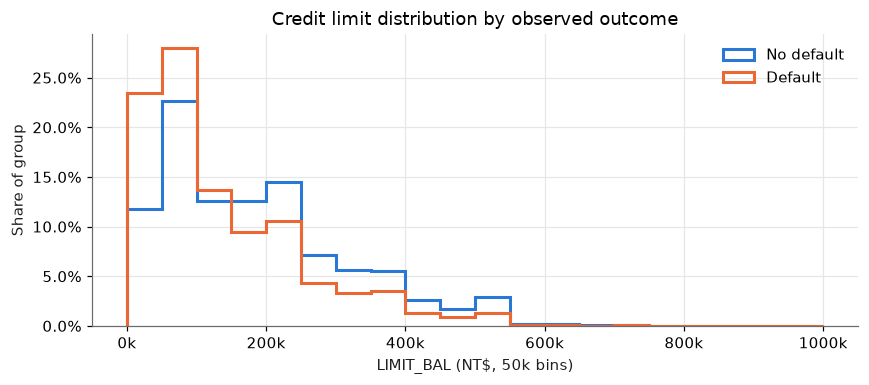

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = range(0, 1_000_001, 50_000)
for label, color, value in [("No default", BLUE, 0), ("Default", ORANGE, 1)]:
    vals = df.loc[df[TARGET] == value, "LIMIT_BAL"]
    ax.hist(vals, bins=bins, weights=[1 / len(vals)] * len(vals), histtype="step", lw=2, color=color, label=label)
ax.set(title="Credit limit distribution by observed outcome", xlabel="LIMIT_BAL (NT$, 50k bins)", ylabel="Share of group")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(frameon=False)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
fig.tight_layout(); fig.savefig(FIG_DIR / "01_limit_bal_by_outcome.png", bbox_inches="tight")

In [10]:
corr = df[BILL_AMOUNTS + PAY_STATUS].corr().loc[BILL_AMOUNTS, BILL_AMOUNTS]
corr.round(2)

,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6
BILL_AMT1,1.00,0.95,0.89,0.86,0.83,0.80
BILL_AMT2,0.95,1.00,0.93,0.89,0.86,0.83
BILL_AMT3,0.89,0.93,1.00,0.92,0.88,0.85
BILL_AMT4,0.86,0.89,0.92,1.00,0.94,0.90
BILL_AMT5,0.83,0.86,0.88,0.94,1.00,0.95
BILL_AMT6,0.80,0.83,0.85,0.90,0.95,1.00


Monthly bill amounts are highly collinear (adjacent months ρ ≈ 0.9). Logistic Regression will need regularisation or aggregated features, and feature importances may be spread across correlated months.

## 4. Reproducible split
Stratified 60/20/20 split with seed 42, stored as customer IDs in `data/processed/splits.json` (produced by `scripts/audit_data.py`).

In [11]:
splits = DataSplits.from_json(resolve_path(cfg["split"]["output_path"]))
by_id = df.set_index("ID")[TARGET]
pd.DataFrame({name: {"n": len(ids), "default_rate": round(by_id.loc[ids].mean(), 4)}
              for name, ids in [("train", splits.train_ids), ("validation", splits.validation_ids), ("test", splits.test_ids)]}).T

,n,default_rate
train,18000.0,0.2212
validation,6000.0,0.2212
test,6000.0,0.2212


## 5. Limitations recorded for the methodology page
- **One cross-section** (April–September 2005, Taiwan). It can't show temporal stability, and it doesn't represent a current portfolio.
- **Target definition** is the one UCI gives. There is no days-past-due rule, so it is not aligned with the Basel/EBA definition of default.
- **Undocumented codes** (`PAY_*` −2/0, `EDUCATION` 0/5/6, `MARRIAGE` 0). Any interpretation of them is an assumption.
- **Protected attributes** (`SEX`, `MARRIAGE`, `AGE`) are used as features at the project owner's request, to maximise predictive performance. Fairness diagnostics will be reported. Real lending use would need a legal and fairness review.
- **Currency:** NT dollars, 2005 values. No monetary loss information (EAD/LGD), so any decision costs are illustrative only.